In [2]:
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt
from scipy import interpolate

%matplotlib inline

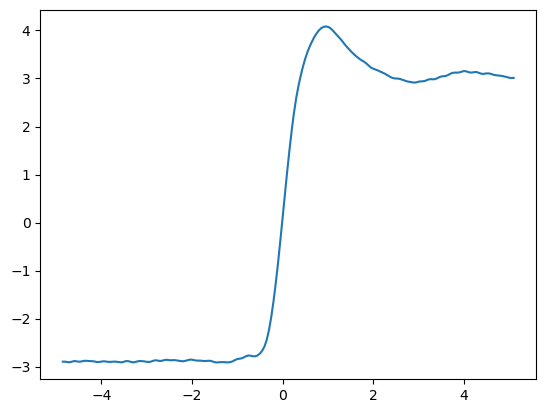

In [3]:
def read_siglent_csv(fn):
    lines = Path(fn).read_text().splitlines()
    return np.loadtxt(lines[lines.index('Second,Value')+1:], delimiter=',')

arr = read_siglent_csv('../data_scope/74lvc_rise_csv.csv')
fig, ax = plt.subplots()
ax.plot(arr[:,0] * 1e9, arr[:,1])

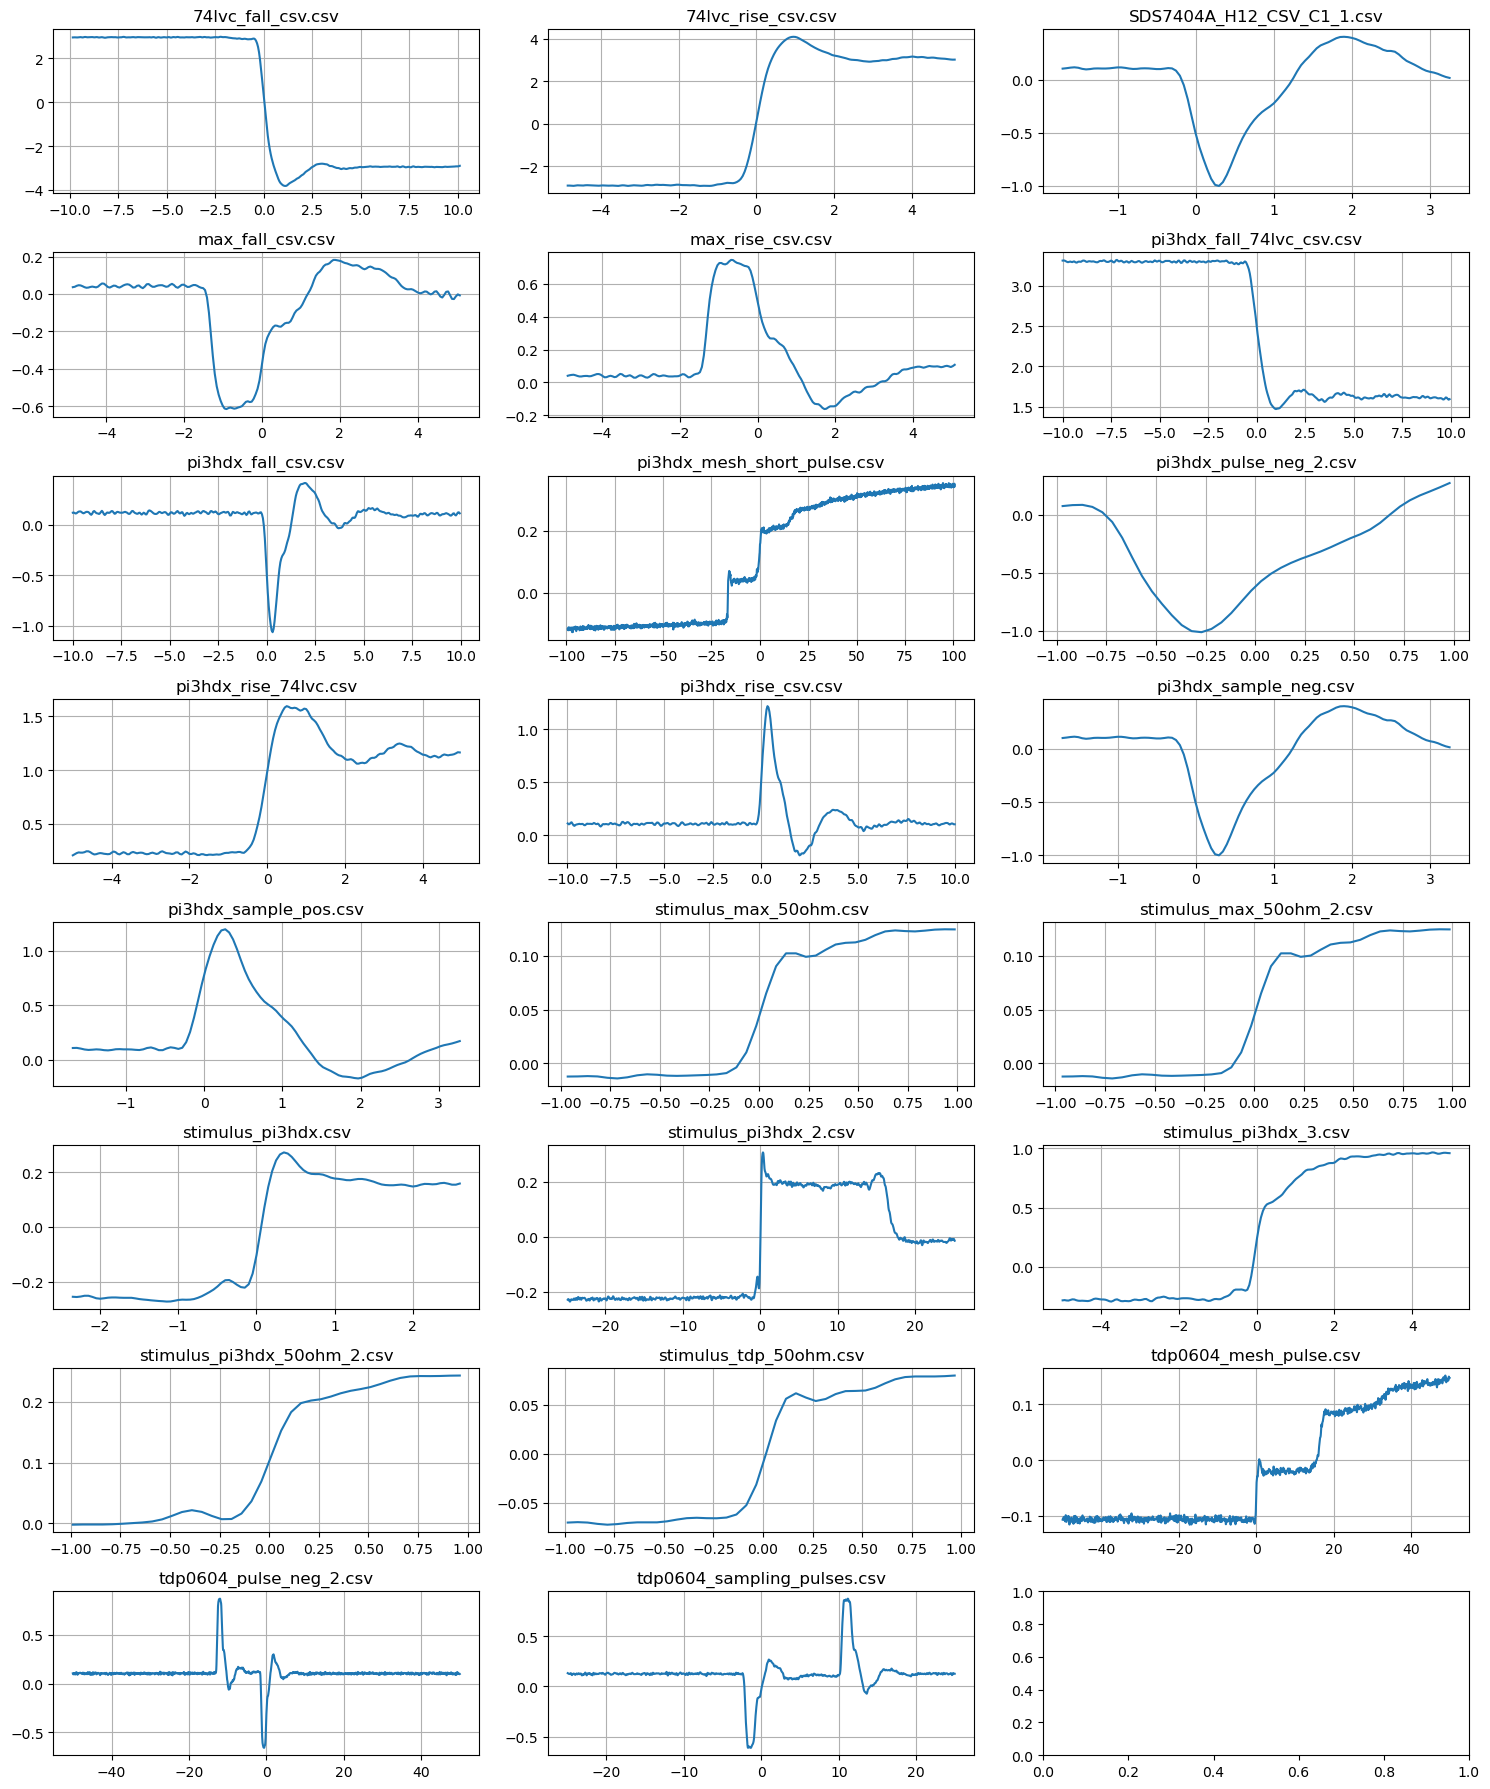

In [4]:
files = list(Path('../data_scope').glob('*.csv'))
fig, axs = plt.subplots((len(files)+2)//3, 3, figsize=(15, 18))

for fn, ax in zip(sorted(files, key=lambda x: x.name), axs.flatten()):
    arr = read_siglent_csv(fn)
    ax.plot(arr[:,0] * 1e9, arr[:,1])
    ax.grid()
    ax.set_title(fn.name)

fig.tight_layout()

              PI3HDX12211: t_r = 224 ps / corrected for scope 195 ps
                  TDP0604: t_r = 181 ps / corrected for scope 144 ps
                  MAX3748: t_r = 183 ps / corrected for scope 146 ps


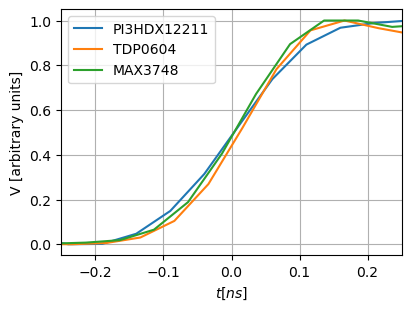

In [12]:
fig, ax = plt.subplots(figsize=(4, 3), constrained_layout=True)

for name, fn in {
    'PI3HDX12211': 'stimulus_pi3hdx_50ohm_2.csv',
    'TDP0604': 'stimulus_tdp_50ohm.csv',
    'MAX3748': 'stimulus_max_50ohm.csv'
    }.items():
    arr = read_siglent_csv(f'../data_scope/{fn}')
    x, y = arr[:,0], arr[:,1]
    x *= 1e9
    
    (a, *_, b), = np.nonzero((-0.35 <= x) & (x <= 0.35))
    x, y = x[a:b], y[a:b]
    
    y -= y.min()
    y /= y.max()

    spl = interpolate.make_smoothing_spline(x, y, lam=1e-12)
    xs = np.linspace(-0.25, 0.25, 5000)
    ys = spl(xs)
    
    (a, *_, b), = np.nonzero((ys >= 0.1) & (ys <= 0.9))
    #print(a, b, ys[a], ys[b], len(ys))
    x1, x2 = xs[a], xs[b]
    tr = x2 - x1
    # Our SDS7404A has a 110 ps typical / 120 ps specified rise time
    tr_c = np.sqrt(tr**2 - 0.110**2)
    
    ax.plot(x, y, label=name)
    #ax.axhline(0.1, color='black', alpha=0.3)
    #ax.axhline(0.9, color='black', alpha=0.3)
    #ax.axvline(x1, color='black', alpha=0.3)
    #ax.axvline(x2, color='black', alpha=0.3)
    print(f'{name:>25}: t_r = {tr*1e3:.0f} ps / corrected for scope {tr_c*1e3:.0f} ps')
    

ax.set_ylabel('V [arbitrary units]')
ax.set_xlabel('$t [ns]$')
ax.set_xlim([-0.25, 0.25])
ax.legend()
ax.grid()
fig.savefig('edge_stimulus_pulse_scope_normalized.pdf')
fig.savefig('edge_stimulus_pulse_scope_normalized.png')

              PI3HDX12211: t_r = 225 ps / corrected for scope and probe 142 ps / effective 201 ps
                  TDP0604: t_r = 321 ps / corrected for scope and probe 270 ps / effective 382 ps
                  MAX3748: t_r = 307 ps / corrected for scope and probe 253 ps / effective 358 ps
74LVC2G157
(right Y axis): t_r = 307 ps / corrected for scope and probe 253 ps / effective 358 ps


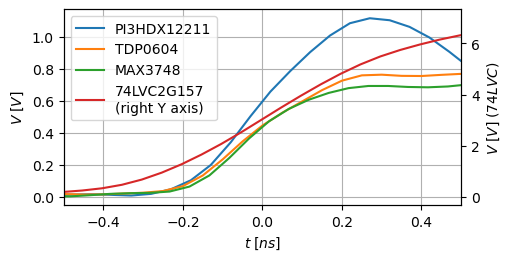

In [38]:
fig, axs = plt.subplots(figsize=(5, 2.5), constrained_layout=True)
tx = axs.twinx()

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
for i, (name, (ax, fn, offset)) in enumerate({
    'PI3HDX12211': (axs, 'pi3hdx_rise_csv.csv', -0.05),
    'TDP0604': (axs, 'tdp0604_sampling_pulses.csv', -10.4),
    'MAX3748': (axs, 'max_rise_csv.csv', 1.25),
    '74LVC2G157\n(right Y axis)': (tx, '74lvc_rise_csv.csv', 0),
    }.items()):
    arr = read_siglent_csv(f'../data_scope/{fn}')
    x, y = arr[:,0], arr[:,1]
    x *= 1e9
    x += offset

    (a, *_, b), = np.nonzero((-1.2 <= x) & (x <= 1.2))
    x, y = x[a:b], y[a:b]
    
    y -= y.min()
    
    spl = interpolate.make_smoothing_spline(x, y, lam=1e-12)
    xs = np.linspace(-0.25, 0.25, 5000)
    ys = spl(xs)

    try:
        (a, *_, b), = np.nonzero((ys >= 0.05) & (ys <= 0.6))
        #print(a, b, ys[a], ys[b], len(ys))
        x1, x2 = xs[a], xs[b]
        tr = x2 - x1
        tr_probe = 0.338 / 2.5 # Estimated probe bandwidth
        # Our SDS7404A has a 110 ps typical / 120 ps specified rise time
        tr_c = np.sqrt(tr**2 - 0.110**2 - tr_probe**2)
    except:
        pass
    
    print(f'{name:>25}: t_r = {tr*1e3:.0f} ps / corrected for scope and probe {tr_c*1e3:.0f} ps / effective {tr_c*np.sqrt(2)*1e3:.0f} ps')
    
    ax.plot(x, y, label=name, color=colors[i])

axs.set_ylabel(r'$V\;[V]$')
tx.set_ylabel(r'$V\;[V]\;(74LVC)$')
axs.set_xlabel(r'$t\;[ns]$')
axs.set_xlim([-.5, .5])
lines1, labels1 = axs.get_legend_handles_labels()
lines2, labels2 = tx.get_legend_handles_labels()
axs.legend(lines1 + lines2, labels1 + labels2, loc='best')
axs.grid()
fig.savefig('edge_sampling_pulse_scope.pdf')

              PI3HDX12211: t_r = 338 ps / corrected for scope and probe 290 ps
                  TDP0604: t_r = 350 ps / corrected for scope and probe 303 ps
                  MAX3748: t_r = 320 ps / corrected for scope and probe 269 ps
               74LVC2G157: t_r = 500 ps / corrected for scope and probe 469 ps


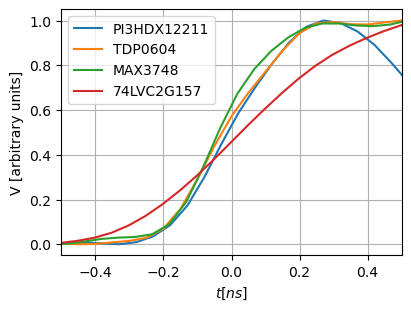

In [21]:
fig, axs = plt.subplots(figsize=(4, 3), constrained_layout=True)

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
for i, (name, (ax, fn, offset)) in enumerate({
    'PI3HDX12211': (axs, 'pi3hdx_rise_csv.csv', -0.05),
    'TDP0604': (axs, 'tdp0604_sampling_pulses.csv', -10.4),
    'MAX3748': (axs, 'max_rise_csv.csv', 1.25),
    '74LVC2G157': (axs, '74lvc_rise_csv.csv', 0),
    }.items()):
    arr = read_siglent_csv(f'../data_scope/{fn}')
    x, y = arr[:,0], arr[:,1]
    x *= 1e9
    x += offset

    (a, *_, b), = np.nonzero((-0.6 <= x) & (x <= 0.6))
    x, y = x[a:b], y[a:b]
    
    y -= y.min()
    y /= y.max()

    spl = interpolate.make_smoothing_spline(x, y, lam=1e-12)
    xs = np.linspace(-0.25, 0.25, 5000)
    ys = spl(xs)

    (a, *_, b), = np.nonzero((ys >= 0.1) & (ys <= 0.9))
    #print(a, b, ys[a], ys[b], len(ys))
    x1, x2 = xs[a], xs[b]
    tr = x2 - x1
    tr_probe = 0.338 / 2.5 # Estimated probe bandwidth
    # Our SDS7404A has a 110 ps typical / 120 ps specified rise time
    tr_c = np.sqrt(tr**2 - 0.110**2 - tr_probe**2)
    
    print(f'{name:>25}: t_r = {tr*1e3:.0f} ps / corrected for scope and probe {tr_c*1e3:.0f} ps')
    ax.plot(x, y, label=name, color=colors[i])

axs.set_ylabel('V [arbitrary units]')
axs.set_xlabel('$t [ns]$')
axs.set_xlim([-.5, .5])
axs.legend()
axs.grid()
fig.savefig('edge_sampling_pulse_scope_normalized.pdf')